# Eksperimen tambahan: CV k=3 dan k=10 (standalone)

## 1. Install & import

In [ ]:
import pyarrow
print(pyarrow.__version__)


23.0.1


In [1]:
!pip install -q transformers datasets accelerate scikit-learn nltk --upgrade


In [2]:
import os, re, time, gc, shutil, pickle, random, inspect, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import binomtest

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score,
                             classification_report, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight
from nltk.stem import PorterStemmer

warnings.filterwarnings("ignore")

# ===================== KONFIGURASI (identik dengan eksperimen k=5) =====================
SEED = 42
FOLD_COUNTS = [3, 10]     # <- khusus k=3 dan k=10 sesuai permintaan dosen pembimbing
RUN_BERT_CV = True        # set False dulu kalau mau cek model klasik aja (cepat), BERT nyusul
BERT_NAME  = "bert-base-uncased"
MAX_LENGTH = 256
EPOCHS     = 5
LEARNING_RATE = 2e-5
BATCH_SIZE = 16
# =========================================================================================

random.seed(SEED); np.random.seed(SEED)
stop_words = set(ENGLISH_STOP_WORDS)
stemmer = PorterStemmer()
print(f"Stopwords: {len(stop_words)} kata | SEED={SEED} | k yang akan dijalankan: {FOLD_COUNTS}")


Stopwords: 318 kata | SEED=42 | k yang akan dijalankan: [3, 10]


## 2. Data: upload, audit, dan pembersihan (kode identik dengan eksperimen k=5)

In [3]:
if not os.path.exists("data.csv"):
    from google.colab import files
    print("Upload data.csv (dataset yang SAMA dengan eksperimen k=5):")
    files.upload()

df_raw = pd.read_csv("data.csv")
print("Bentuk data :", df_raw.shape)
print("Kolom       :", list(df_raw.columns))
print("\nDistribusi genre (data asli):\n", df_raw['genre'].value_counts())


Upload data.csv (dataset yang SAMA dengan eksperimen k=5):


Saving data.csv to data.csv
Bentuk data : (4657, 4)
Kolom       : ['index', 'title', 'genre', 'summary']

Distribusi genre (data asli):
 genre
thriller      1023
fantasy        876
science        647
history        600
horror         600
crime          500
romance        111
psychology     100
sports         100
travel         100
Name: count, dtype: int64


In [4]:
# ---- Audit kualitas data + pembersihan (identik dengan eksperimen k=5) ----
df_raw = df_raw.dropna(subset=['summary', 'genre']).reset_index(drop=True)
n_raw = len(df_raw)
dup_rows   = int(df_raw.duplicated(subset='summary', keep=False).sum())
n_conflict = int(df_raw.groupby('summary')['genre'].nunique().gt(1).sum())

n_labels = df_raw.groupby('summary')['genre'].transform('nunique')
df = df_raw[n_labels == 1].drop_duplicates(subset='summary').reset_index(drop=True)

print(f"Data asli                 : {n_raw}")
print(f"Baris terlibat duplikat   : {dup_rows} ({dup_rows/n_raw*100:.1f}%)")
print(f"Sinopsis berlabel konflik : {n_conflict}")
print(f"Data setelah dibersihkan  : {len(df)}  (dibuang {n_raw-len(df)} baris = {(n_raw-len(df))/n_raw*100:.1f}%)")
assert len(df) == 4446, f"PERINGATAN: jumlah data bersih ({len(df)}) beda dari eksperimen k=5 (4446) -> data.csv yang di-upload mungkin bukan yang sama!"


Data asli                 : 4657
Baris terlibat duplikat   : 228 (4.9%)
Sinopsis berlabel konflik : 96
Data setelah dibersihkan  : 4446  (dibuang 211 baris = 4.5%)


## 3. Preprocessing teks (kode identik)

In [6]:
def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = text.split()
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]
    tokens = [stemmer.stem(t) for t in tokens]
    return ' '.join(tokens)

t0 = time.time()
df['clean_summary'] = df['summary'].apply(preprocess_text)
print(f"Preprocessing selesai dalam {time.time()-t0:.0f} detik")
display(df[['summary', 'clean_summary']].head(3))


Preprocessing selesai dalam 24 detik


,summary,clean_summary
0,Drowned Wednesday is the first Trustee among ...,drown wednesday truste morrow day arthur wish ...
1,"As the book opens, Jason awakens on a school ...",book open jason awaken school bu unabl rememb ...
2,Cugel is easily persuaded by the merchant Fia...,cugel easili persuad merchant fianosth attempt...


## 4. Label encoding (tanpa split tetap — notebook ini cuma buat CV)

In [7]:
le = LabelEncoder()
df['label'] = le.fit_transform(df['genre'])
label_names = le.classes_
num_labels = len(label_names)
print("Jumlah kelas:", num_labels, dict(enumerate(label_names)))

X_txt = df['clean_summary'].values
y_all = df['label'].values


Jumlah kelas: 10 {0: 'crime', 1: 'fantasy', 2: 'history', 3: 'horror', 4: 'psychology', 5: 'romance', 6: 'science', 7: 'sports', 8: 'thriller', 9: 'travel'}


In [8]:
import hashlib
from sklearn.model_selection import StratifiedKFold
print(hashlib.md5(''.join(df['summary'].astype(str)).encode()).hexdigest())
folds = list(StratifiedKFold(n_splits=10, shuffle=True, random_state=42).split(df.index.values, df['label'].values))
print(hashlib.md5(str([te.tolist() for _, te in folds]).encode()).hexdigest())

1ec124d4c29c1aae23dbc8ec8fceccf9
1fc2b10bf533dbb1a60f9307a374da92


## 5. Fungsi bersama: model klasik, BERT, dan uji McNemar

In [9]:
def make_models():
    return {
        "RF  (top500, tanpa balancing)": Pipeline([("tf", TfidfVectorizer(max_features=500)),
            ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]),
        "RF  (top500, class_weight)": Pipeline([("tf", TfidfVectorizer(max_features=500)),
            ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1))]),
        "LR  (top500, class_weight)": Pipeline([("tf", TfidfVectorizer(max_features=500)),
            ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        "LR  (vocab penuh, 1-2gram)": Pipeline([("tf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
            ("clf", LogisticRegression(C=10, max_iter=3000, class_weight="balanced"))]),
        "SVM (vocab penuh, 1-2gram)": Pipeline([("tf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
            ("clf", LinearSVC(C=0.5, class_weight="balanced", max_iter=5000, random_state=SEED))]),
    }

def mcnemar_exact(y_true, pred_a, pred_b):
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    a_ok, b_ok = (pred_a == y_true), (pred_b == y_true)
    n01 = int(np.sum(a_ok & ~b_ok))
    n10 = int(np.sum(~a_ok & b_ok))
    n = n01 + n10
    p = binomtest(min(n01, n10), n, 0.5).pvalue if n > 0 else 1.0
    return n01, n10, p


In [10]:
import torch
import torch.nn as nn
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
print("Device:", device)
if RUN_BERT_CV and device.type != "cuda":
    print("PERINGATAN: GPU tidak aktif. Ganti runtime ke T4 GPU sebelum menjalankan BERT.")

tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)

def to_ds(frame):
    ds = Dataset.from_pandas(frame[['summary', 'label']].reset_index(drop=True))
    ds = ds.map(lambda b: tokenizer(b['summary'], truncation=True, padding='max_length', max_length=MAX_LENGTH), batched=True)
    ds = ds.rename_column("label", "labels")
    ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
    return ds

class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = nn.CrossEntropyLoss(weight=self.class_weights)(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def bert_metrics(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p),
            "f1_macro": f1_score(labels, p, average="macro"),
            "kappa": cohen_kappa_score(labels, p)}

def make_training_args(out_dir, n_train):
    params = inspect.signature(TrainingArguments.__init__).parameters
    kw = dict(output_dir=out_dir, learning_rate=LEARNING_RATE,
              per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=32,
              num_train_epochs=EPOCHS, weight_decay=0.01,
              load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
              seed=SEED, logging_steps=100, report_to="none")
    if "eval_strategy" in params:         kw["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in params: kw["evaluation_strategy"] = "epoch"
    if "save_strategy" in params:         kw["save_strategy"] = "epoch"
    if "save_total_limit" in params:      kw["save_total_limit"] = 1
    if "warmup_ratio" in params:          kw["warmup_ratio"] = 0.1
    elif "warmup_steps" in params:        kw["warmup_steps"] = int(0.1 * (n_train // BATCH_SIZE) * EPOCHS)
    return TrainingArguments(**kw)

def run_bert(train_part, val_part, test_part, tag):
    w = compute_class_weight('balanced', classes=np.unique(train_part['label']), y=train_part['label'])
    w = torch.tensor(w, dtype=torch.float).to(device)
    tr, va, te = to_ds(train_part), to_ds(val_part), to_ds(test_part)
    model = AutoModelForSequenceClassification.from_pretrained(BERT_NAME, num_labels=num_labels).to(device)
    out_dir = f"./bert_{tag}"
    trainer = WeightedTrainer(model=model, args=make_training_args(out_dir, len(tr)),
                              train_dataset=tr, eval_dataset=va, compute_metrics=bert_metrics,
                              callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
                              class_weights=w)
    t0 = time.time(); trainer.train(); elapsed = time.time() - t0
    out = trainer.predict(te)
    y_true, y_pred = out.label_ids, np.argmax(out.predictions, axis=-1)
    del model, trainer
    gc.collect(); torch.cuda.empty_cache(); shutil.rmtree(out_dir, ignore_errors=True)
    return {"y_true": y_true, "y_pred": y_pred, "time_sec": elapsed}

print("Fungsi BERT siap.")


Device: cuda


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Fungsi BERT siap.


## 6. Fungsi CV per-k (checkpoint terpisah per k, aman dilanjut kalau terputus)

In [11]:
data_sig = hashlib.md5(''.join(df['summary'].astype(str)).encode()).hexdigest()

def run_full_cv(k, run_bert_cv=True):
    out_dir = f"hasil/cv_k{k}"
    os.makedirs(out_dir, exist_ok=True)

    skf_k = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
    folds_k = list(skf_k.split(df.index.values, y_all))

    # ---- model klasik ----
    oof_pred_k = {name: np.zeros(len(df), dtype=int) for name in make_models()}
    cv_rows = []
    for fold, (tr, te) in enumerate(folds_k, start=1):
        for name, model in make_models().items():
            t0 = time.time()
            model.fit(X_txt[tr], y_all[tr])
            p = model.predict(X_txt[te])
            oof_pred_k[name][te] = p
            cv_rows.append({"model": name, "fold": fold, "acc": accuracy_score(y_all[te], p) * 100,
                            "f1_macro": f1_score(y_all[te], p, average="macro"),
                            "kappa": cohen_kappa_score(y_all[te], p), "time_sec": time.time() - t0})
        print(f"[k={k}] fold klasik {fold}/{k} selesai")
    cv_klasik_k = pd.DataFrame(cv_rows)

    # ---- BERT CV, checkpoint per-k ----
    ckpt_path = f"{out_dir}/bert_cv_results_k{k}.pkl"
    bert_results_k = []
    if os.path.exists(ckpt_path):
        saved = pickle.load(open(ckpt_path, "rb"))
        if saved.get("sig") == data_sig and saved.get("n_folds") == k:
            bert_results_k = saved["results"]
            print(f"[k={k}] melanjutkan checkpoint BERT: {len(bert_results_k)} fold sudah selesai.")
        else:
            print(f"[k={k}] checkpoint lama tidak cocok (data/k beda) -> diabaikan.")

    if run_bert_cv:
        done = {r["fold"] for r in bert_results_k}
        for fold, (tr_idx, te_idx) in enumerate(folds_k, start=1):
            if fold in done:
                continue
            tv_part, te_part = df.iloc[tr_idx], df.iloc[te_idx]
            tr_part, va_part = train_test_split(tv_part, test_size=0.15, stratify=tv_part['label'], random_state=SEED)
            r = run_bert(tr_part, va_part, te_part, f"cvk{k}f{fold}")
            rec = {"fold": fold, "idx": te_part.index.values, "y_true": r["y_true"], "y_pred": r["y_pred"], "time_sec": r["time_sec"]}
            bert_results_k.append(rec)
            pickle.dump({"sig": data_sig, "n_folds": k, "results": bert_results_k}, open(ckpt_path, "wb"))
            print(f"[k={k}] === Fold {fold}/{k} BERT === acc {accuracy_score(r['y_true'], r['y_pred'])*100:.2f}% | "
                  f"F1-macro {f1_score(r['y_true'], r['y_pred'], average='macro'):.3f} | {r['time_sec']/60:.1f} menit")
    else:
        print(f"[k={k}] run_bert_cv=False: BERT CV dilewati.")
    bert_results_k = sorted(bert_results_k, key=lambda r: r["fold"])

    bert_rows_k = []
    for r in bert_results_k:
        bert_rows_k.append({"model": "BERT (weighted loss)", "fold": r["fold"],
                            "acc": accuracy_score(r["y_true"], r["y_pred"]) * 100,
                            "f1_macro": f1_score(r["y_true"], r["y_pred"], average="macro"),
                            "kappa": cohen_kappa_score(r["y_true"], r["y_pred"]), "time_sec": r["time_sec"]})
    cv_all_k = pd.concat([cv_klasik_k, pd.DataFrame(bert_rows_k)], ignore_index=True)
    g = cv_all_k.groupby("model").agg(acc_mean=("acc", "mean"), acc_std=("acc", "std"),
                                      f1_mean=("f1_macro", "mean"), f1_std=("f1_macro", "std"),
                                      kappa_mean=("kappa", "mean"), kappa_std=("kappa", "std"),
                                      waktu_per_fold_detik=("time_sec", "mean"), n_fold=("fold", "count"))
    cv_summary_k = g.sort_values("f1_mean", ascending=False).round(3)
    cv_summary_k.insert(0, "k", k)

    bert_oof_k = None
    if len(bert_results_k) == k:
        bert_oof_k = np.zeros(len(df), dtype=int)
        for r in bert_results_k:
            bert_oof_k[r["idx"]] = r["y_pred"]
        assert all((r["y_true"] == y_all[r["idx"]]).all() for r in bert_results_k), "indeks fold tidak selaras"

    cv_all_k.to_csv(f"{out_dir}/cv_per_fold_k{k}.csv", index=False)
    cv_summary_k.to_csv(f"{out_dir}/ringkasan_cv_k{k}.csv")

    return {"k": k, "cv_all": cv_all_k, "oof_pred": oof_pred_k,
            "bert_results": bert_results_k, "bert_oof": bert_oof_k, "cv_summary": cv_summary_k}

print("run_full_cv(k) siap.")


run_full_cv(k) siap.


## 7. Jalankan k=3 dan k=10

In [ ]:
cv_multi = {}
for k in FOLD_COUNTS:
    res = run_full_cv(k, run_bert_cv=RUN_BERT_CV)
    res["cv_summary"] = res["cv_summary"].reset_index()[["k", "model", "acc_mean", "acc_std",
                                                           "f1_mean", "f1_std", "kappa_mean", "kappa_std",
                                                           "waktu_per_fold_detik", "n_fold"]]
    cv_multi[k] = res

print("Selesai. k yang tersedia:", sorted(cv_multi.keys()))


[k=3] fold klasik 1/3 selesai
[k=3] fold klasik 2/3 selesai
[k=3] fold klasik 3/3 selesai


Map:   0%|          | 0/2519 [00:00<?, ? examples/s]

Map:   0%|          | 0/445 [00:00<?, ? examples/s]

Map:   0%|          | 0/1482 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

[k=10] === Fold 10/10 BERT === acc 79.05% | F1-macro 0.817 | 15.7 menit
Selesai. k yang tersedia: [3, 10]


## 8. Tabel & grafik perbandingan k=3 vs k=10

(Opsional: kalau kamu punya `ringkasan_cv.csv` dari eksperimen k=5 sebelumnya, upload ke runtime ini lalu jalankan cell opsional di bawah supaya grafiknya jadi 3-arah k=3/5/10. Kalau enggak, langsung lanjut ke cell berikutnya buat bandingin k=3 vs k=10 aja.)

In [ ]:
# Opsional: gabungkan dengan hasil k=5 kalau filenya ada (upload manual ke runtime kalau mau dipakai)
k5_path_candidates = ["ringkasan_cv.csv", "hasil/ringkasan_cv.csv"]
k5_summary = None
for p in k5_path_candidates:
    if os.path.exists(p):
        k5_raw = pd.read_csv(p)
        k5_raw = k5_raw.rename(columns={k5_raw.columns[0]: "model"}) if "model" not in k5_raw.columns else k5_raw
        k5_raw["k"] = 5
        k5_summary = k5_raw
        print("Hasil k=5 ditemukan di", p, "-> ikut dimasukkan ke perbandingan.")
        break
if k5_summary is None:
    print("Hasil k=5 tidak ditemukan di runtime ini -> perbandingan cuma k=3 vs k=10. "
          "(Upload ringkasan_cv.csv dari eksperimen k=5 lalu jalankan ulang cell ini kalau mau 3-arah.)")


Hasil k=5 tidak ditemukan di runtime ini -> perbandingan cuma k=3 vs k=10. (Upload ringkasan_cv.csv dari eksperimen k=5 lalu jalankan ulang cell ini kalau mau 3-arah.)


,k,model,acc_mean,acc_std,f1_mean,f1_std,kappa_mean,kappa_std,waktu_per_fold_detik,n_fold
0,3,BERT (weighted loss),75.821,1.902,0.791,0.025,0.716,0.022,685.465,3
1,10,BERT (weighted loss),76.945,2.318,0.802,0.024,0.729,0.027,916.179,10
2,3,"LR (top500, class_weight)",60.999,1.135,0.577,0.017,0.547,0.012,1.129,3
3,10,"LR (top500, class_weight)",61.089,3.473,0.577,0.040,0.548,0.039,0.996,10
4,3,"LR (vocab penuh, 1-2gram)",74.719,0.439,0.734,0.009,0.700,0.005,11.267,3
5,10,"LR (vocab penuh, 1-2gram)",75.979,2.192,0.758,0.031,0.716,0.026,16.962,10
6,3,"RF (top500, class_weight)",56.388,0.955,0.521,0.007,0.492,0.010,7.865,3
7,10,"RF (top500, class_weight)",57.378,2.633,0.536,0.027,0.503,0.030,11.982,10
8,3,"RF (top500, tanpa balancing)",57.782,0.945,0.418,0.007,0.489,0.011,9.498,3
9,10,"RF (top500, tanpa balancing)",59.042,3.350,0.442,0.024,0.505,0.041,14.094,10


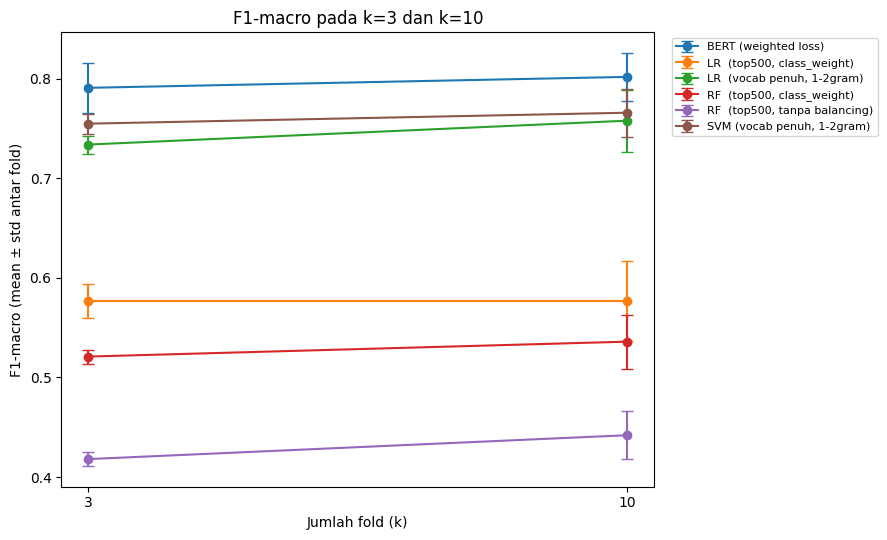


Catatan buat laporan:
- k=3: tiap fold dilatih dgn ~67% data -> cenderung sedikit pesimistis (bias naik), tapi cuma 3
  estimasi jadi rata-ratanya lebih goyah antar-fold (std bisa naik).
- k=10: tiap fold dilatih dgn ~90% data -> bias turun (lebih dekat performa di seluruh data), dan
  rata-rata dari 10 estimasi umumnya lebih stabil, walau tiap fold uji lebih kecil (noisy per-fold).
- Kesimpulan (mis. BERT > SVM) dibilang robust kalau arahnya konsisten di k=3 dan k=10, bukan cuma
  kebetulan di satu nilai k.


In [ ]:
combined = pd.concat([cv_multi[k]["cv_summary"] for k in sorted(cv_multi)], ignore_index=True)
if k5_summary is not None:
    cols = [c for c in combined.columns if c in k5_summary.columns]
    combined = pd.concat([combined, k5_summary[cols]], ignore_index=True)
combined = combined.sort_values(["model", "k"]).reset_index(drop=True)
display(combined)
os.makedirs("hasil", exist_ok=True)
combined.to_csv("hasil/perbandingan_k3_k10.csv", index=False)

plt.figure(figsize=(9, 5.5))
for name, grp in combined.groupby("model"):
    grp = grp.sort_values("k")
    plt.errorbar(grp["k"], grp["f1_mean"], yerr=grp["f1_std"], marker="o", capsize=4, label=name)
plt.xlabel("Jumlah fold (k)"); plt.ylabel("F1-macro (mean ± std antar fold)")
plt.title("F1-macro pada k=3 dan k=10" + (" (+ k=5)" if k5_summary is not None else ""))
plt.xticks(sorted(combined["k"].unique()))
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig("hasil/f1_vs_k.png", dpi=150); plt.show()

print("\nCatatan buat laporan:")
print("- k=3: tiap fold dilatih dgn ~67% data -> cenderung sedikit pesimistis (bias naik), tapi cuma 3")
print("  estimasi jadi rata-ratanya lebih goyah antar-fold (std bisa naik).")
print("- k=10: tiap fold dilatih dgn ~90% data -> bias turun (lebih dekat performa di seluruh data), dan")
print("  rata-rata dari 10 estimasi umumnya lebih stabil, walau tiap fold uji lebih kecil (noisy per-fold).")
print("- Kesimpulan (mis. BERT > SVM) dibilang robust kalau arahnya konsisten di k=3 dan k=10, bukan cuma")
print("  kebetulan di satu nilai k.")


## 10. Cek kewarasan & unduh hasil

In [ ]:
for k in sorted(cv_multi):
    res = cv_multi[k]
    print(f"[k={k}] jumlah data uji out-of-fold terkumpul (model klasik) :", sum(len(te) for _, te in StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED).split(df.index.values, y_all)))
    if res["bert_oof"] is not None:
        bert_acc = accuracy_score(y_all, res["bert_oof"]) * 100
        print(f"[k={k}] BERT out-of-fold accuracy: {bert_acc:.2f}%  (bandingkan kewajaran dgn k=5: ~76.9%)")

print("\nIsi folder hasil/:")
for root, dirs, files in os.walk("hasil"):
    for f in files:
        print(os.path.join(root, f))

try:
    from google.colab import files
    shutil.make_archive("hasil_cv_k3_k10", "zip", "hasil")
    files.download("hasil_cv_k3_k10.zip")
except Exception as e:
    print("Unduh manual folder hasil/ (bukan di Colab):", type(e).__name__)


[k=3] jumlah data uji out-of-fold terkumpul (model klasik) : 4446
[k=3] BERT out-of-fold accuracy: 75.82%  (bandingkan kewajaran dgn k=5: ~76.9%)
[k=10] jumlah data uji out-of-fold terkumpul (model klasik) : 4446
[k=10] BERT out-of-fold accuracy: 76.95%  (bandingkan kewajaran dgn k=5: ~76.9%)

Isi folder hasil/:
hasil/f1_vs_k.png
hasil/perbandingan_k3_k10.csv
hasil/cv_k3/cv_per_fold_k3.csv
hasil/cv_k3/bert_cv_results_k3.pkl
hasil/cv_k3/ringkasan_cv_k3.csv
hasil/cv_k10/ringkasan_cv_k10.csv
hasil/cv_k10/cv_per_fold_k10.csv
hasil/cv_k10/bert_cv_results_k10.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

RF full vocab

In [ ]:
# %% CELL 1 : definisi + jalankan (ada checkpoint per fold, aman kalau runtime terputus)
RF_KS = [3, 10]      # boleh [3, 5, 10] kalau mau sekalian k=5 (fungsi ini tidak butuh cv_multi[5])
RF_VARIAN = {        # nama model -> class_weight
    "RF  (vocab penuh, 1-2gram, tanpa balancing)": None,
    "RF  (vocab penuh, 1-2gram, class_weight)": "balanced",
}
KODE_BARU = {"RF  (vocab penuh, 1-2gram, tanpa balancing)": "A4",
             "RF  (vocab penuh, 1-2gram, class_weight)": "A5"}

if "data_sig" not in globals():
    data_sig = hashlib.md5(''.join(df['summary'].astype(str)).encode()).hexdigest()

def make_rf_full(class_weight):
    # TF-IDF IDENTIK dengan B3/B4, hanya pengklasifikasinya RF
    return Pipeline([
        ("tf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf", RandomForestClassifier(n_estimators=300, class_weight=class_weight,
                                       random_state=SEED, n_jobs=-1)),
    ])

def run_rf_full(k):
    out_dir = f"hasil/cv_k{k}"
    os.makedirs(out_dir, exist_ok=True)
    ckpt = f"{out_dir}/rf_full_k{k}.pkl"
    folds_k = list(StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
                   .split(df.index.values, y_all))

    state = {"sig": data_sig, "k": k, "rows": [], "done": set(),
             "oof": {n: np.zeros(len(df), dtype=int) for n in RF_VARIAN}}
    if os.path.exists(ckpt):
        saved = pickle.load(open(ckpt, "rb"))
        if saved.get("sig") == data_sig and saved.get("k") == k and set(saved["oof"]) == set(RF_VARIAN):
            state = saved
            print(f"[k={k}] melanjutkan checkpoint: {len(state['done'])}/{k} fold sudah selesai.")
        else:
            print(f"[k={k}] checkpoint lama tidak cocok -> diabaikan.")

    for fold, (tr, te) in enumerate(folds_k, start=1):
        if fold in state["done"]:
            continue
        for name, cw in RF_VARIAN.items():
            t0 = time.time()
            m = make_rf_full(cw).fit(X_txt[tr], y_all[tr])
            p = m.predict(X_txt[te])
            state["oof"][name][te] = p
            state["rows"].append({"model": name, "fold": fold,
                                  "acc": accuracy_score(y_all[te], p) * 100,
                                  "f1_macro": f1_score(y_all[te], p, average="macro"),
                                  "kappa": cohen_kappa_score(y_all[te], p),
                                  "time_sec": time.time() - t0})
        state["done"].add(fold)
        pickle.dump(state, open(ckpt, "wb"))
        last = [r for r in state["rows"] if r["fold"] == fold]
        print(f"[k={k}] fold {fold}/{k} selesai | " +
              " | ".join(f"{KODE_BARU[r['model']]}: acc {r['acc']:.1f}% F1 {r['f1_macro']:.3f} ({r['time_sec']:.0f} dtk)"
                         for r in last))
    return state

def ringkas_rf(rows, k):
    d = pd.DataFrame(rows)
    g = d.groupby("model").agg(acc_mean=("acc", "mean"), acc_std=("acc", "std"),
                               f1_mean=("f1_macro", "mean"), f1_std=("f1_macro", "std"),
                               kappa_mean=("kappa", "mean"), kappa_std=("kappa", "std"),
                               waktu_per_fold_detik=("time_sec", "mean"),
                               n_fold=("fold", "count")).round(3).reset_index()
    g.insert(0, "k", k)
    return g

rf_full = {}
for k in RF_KS:
    t0 = time.time()
    rf_full[k] = run_rf_full(k)
    print(f"[k={k}] RF vocab penuh selesai dalam {(time.time()-t0)/60:.1f} menit\n")

# ---- gabungkan ke cv_multi (jika k itu ada) supaya cell visualisasi lama tetap jalan ----
for k, st in rf_full.items():
    summ = ringkas_rf(st["rows"], k)
    if k in cv_multi:
        res = cv_multi[k]
        res["cv_all"] = pd.concat([res["cv_all"][~res["cv_all"]["model"].isin(RF_VARIAN)],
                                   pd.DataFrame(st["rows"])], ignore_index=True)
        res["oof_pred"].update(st["oof"])
        res["cv_summary"] = pd.concat([res["cv_summary"][~res["cv_summary"]["model"].isin(RF_VARIAN)],
                                       summ], ignore_index=True)
    st["summary"] = summ

# daftarkan kode A4/A5 untuk cell visualisasi (kalau cell 27 sudah dijalankan)
_norm = lambda s: re.sub(r"\s+", " ", s).strip()
if "KODE_MAP" in globals():
    for n, c in KODE_BARU.items(): KODE_MAP[_norm(n)] = c
if "PENDEK" in globals():
    PENDEK.update({"A4": "RF kosakata penuh, tanpa penyeimbangan", "A5": "RF kosakata penuh, bobot kelas"})
if "URUT" in globals():
    URUT[:] = [u for u in URUT if u not in ("A4", "A5")]
    URUT[URUT.index("A3") + 1:URUT.index("A3") + 1] = ["A4", "A5"] if "A3" in URUT else []
if "WARNA" in globals():
    import seaborn as _sns
    _pal = _sns.color_palette("colorblind", 12)
    WARNA.setdefault("A4", _pal[8]); WARNA.setdefault("A5", _pal[9])



[k=3] fold 1/3 selesai | A4: acc 61.1% F1 0.427 (24 dtk) | A5: acc 62.9% F1 0.616 (19 dtk)
[k=3] fold 2/3 selesai | A4: acc 59.6% F1 0.428 (27 dtk) | A5: acc 64.2% F1 0.629 (24 dtk)
[k=3] fold 3/3 selesai | A4: acc 60.1% F1 0.381 (26 dtk) | A5: acc 63.4% F1 0.649 (23 dtk)
[k=3] RF vocab penuh selesai dalam 2.4 menit

[k=10] fold 1/10 selesai | A4: acc 63.1% F1 0.451 (41 dtk) | A5: acc 67.0% F1 0.636 (33 dtk)
[k=10] fold 2/10 selesai | A4: acc 62.0% F1 0.458 (44 dtk) | A5: acc 60.4% F1 0.602 (37 dtk)
[k=10] fold 3/10 selesai | A4: acc 62.0% F1 0.444 (43 dtk) | A5: acc 65.2% F1 0.610 (35 dtk)
[k=10] fold 4/10 selesai | A4: acc 62.7% F1 0.420 (43 dtk) | A5: acc 65.2% F1 0.620 (35 dtk)
[k=10] fold 5/10 selesai | A4: acc 55.1% F1 0.399 (45 dtk) | A5: acc 60.7% F1 0.647 (39 dtk)
[k=10] fold 6/10 selesai | A4: acc 59.6% F1 0.404 (44 dtk) | A5: acc 67.2% F1 0.677 (38 dtk)
[k=10] fold 7/10 selesai | A4: acc 63.5% F1 0.448 (43 dtk) | A5: acc 64.4% F1 0.593 (38 dtk)
[k=10] fold 8/10 selesai | A4:

In [ ]:
# %% CELL 2 : tabel perbandingan lengkap + F1 per genre (OOF)
cols = ["k", "model", "acc_mean", "acc_std", "f1_mean", "f1_std", "kappa_mean", "waktu_per_fold_detik"]
rf_sum_all = pd.concat([st["summary"] for st in rf_full.values()], ignore_index=True)
if "combined" in globals():
    base = combined.copy()
else:
    base = pd.concat([cv_multi[k]["cv_summary"] for k in sorted(cv_multi)], ignore_index=True)
base = base[~base["model"].isin(RF_VARIAN)]
tabel = pd.concat([base, rf_sum_all], ignore_index=True)
tabel = tabel[tabel["k"].isin(RF_KS)].sort_values(["k", "f1_mean"], ascending=[True, False])
for k in sorted(tabel["k"].unique()):
    print(f"\n=== k = {k} (urut F1-macro) ===")
    display(tabel[tabel["k"] == k][cols[1:]].reset_index(drop=True))
os.makedirs("hasil", exist_ok=True)
tabel.to_csv("hasil/perbandingan_dengan_rf_vocab_penuh.csv", index=False)

# F1 per genre (out-of-fold) -> kelas minoritas
idx_lbl = np.arange(num_labels)
for k in RF_KS:
    cols_g = {"genre": label_names, "support": np.bincount(y_all, minlength=num_labels)}
    for name, pred in {**cv_multi.get(k, {}).get("oof_pred", {}), **rf_full[k]["oof"]}.items():
        cols_g[_norm(name)] = f1_score(y_all, pred, average=None, labels=idx_lbl)
    if cv_multi.get(k, {}).get("bert_oof") is not None:
        cols_g["BERT"] = f1_score(y_all, cv_multi[k]["bert_oof"], average=None, labels=idx_lbl)
    pg = pd.DataFrame(cols_g).round(3)
    print(f"\nF1 per genre, out-of-fold, k={k}:")
    display(pg)
    pg.to_csv(f"hasil/f1_per_genre_rf_vocab_penuh_k{k}.csv", index=False)



=== k = 3 (urut F1-macro) ===


,model,acc_mean,acc_std,f1_mean,f1_std,kappa_mean,waktu_per_fold_detik
0,BERT (weighted loss),75.821,1.902,0.791,0.025,0.716,685.465
1,"SVM (vocab penuh, 1-2gram)",75.259,0.384,0.755,0.010,0.708,1.831
2,"LR (vocab penuh, 1-2gram)",74.719,0.439,0.734,0.009,0.700,11.267
3,"RF (vocab penuh, 1-2gram, class_weight)",63.473,0.648,0.631,0.017,0.569,22.165
4,"LR (top500, class_weight)",60.999,1.135,0.577,0.017,0.547,1.129
5,"RF (top500, class_weight)",56.388,0.955,0.521,0.007,0.492,7.865
6,"RF (top500, tanpa balancing)",57.782,0.945,0.418,0.007,0.489,9.498
7,"RF (vocab penuh, 1-2gram, tanpa balancing)",60.279,0.722,0.412,0.027,0.515,25.579



=== k = 10 (urut F1-macro) ===


,model,acc_mean,acc_std,f1_mean,f1_std,kappa_mean,waktu_per_fold_detik
0,BERT (weighted loss),76.945,2.318,0.802,0.024,0.729,916.179
1,"SVM (vocab penuh, 1-2gram)",76.136,2.588,0.766,0.024,0.719,2.086
2,"LR (vocab penuh, 1-2gram)",75.979,2.192,0.758,0.031,0.716,16.962
3,"RF (vocab penuh, 1-2gram, class_weight)",64.373,2.265,0.636,0.029,0.580,36.959
4,"LR (top500, class_weight)",61.089,3.473,0.577,0.040,0.548,0.996
5,"RF (top500, class_weight)",57.378,2.633,0.536,0.027,0.503,11.982
6,"RF (top500, tanpa balancing)",59.042,3.350,0.442,0.024,0.505,14.094
7,"RF (vocab penuh, 1-2gram, tanpa balancing)",61.247,2.464,0.429,0.025,0.528,42.883



F1 per genre, out-of-fold, k=3:


,genre,support,"RF (top500, tanpa balancing)","RF (top500, class_weight)","LR (top500, class_weight)","LR (vocab penuh, 1-2gram)","SVM (vocab penuh, 1-2gram)","RF (vocab penuh, 1-2gram, tanpa balancing)","RF (vocab penuh, 1-2gram, class_weight)",BERT
0,crime,500,0.545,0.577,0.618,0.737,0.729,0.545,0.617,0.706
1,fantasy,850,0.657,0.624,0.660,0.784,0.793,0.662,0.672,0.805
2,history,586,0.631,0.609,0.658,0.766,0.765,0.643,0.668,0.800
3,horror,571,0.469,0.487,0.569,0.694,0.696,0.459,0.548,0.650
4,psychology,87,0.044,0.376,0.554,0.821,0.829,0.067,0.770,0.870
5,romance,76,0.074,0.392,0.380,0.408,0.537,0.000,0.190,0.739
6,science,621,0.662,0.657,0.668,0.777,0.781,0.724,0.708,0.795
7,sports,80,0.176,0.490,0.498,0.838,0.864,0.330,0.877,0.932
8,thriller,977,0.563,0.500,0.563,0.722,0.726,0.609,0.561,0.726
9,travel,98,0.369,0.486,0.598,0.800,0.837,0.097,0.709,0.884



F1 per genre, out-of-fold, k=10:


,genre,support,"RF (top500, tanpa balancing)","RF (top500, class_weight)","LR (top500, class_weight)","LR (vocab penuh, 1-2gram)","SVM (vocab penuh, 1-2gram)","RF (vocab penuh, 1-2gram, tanpa balancing)","RF (vocab penuh, 1-2gram, class_weight)",BERT
0,crime,500,0.562,0.585,0.622,0.745,0.735,0.566,0.624,0.696
1,fantasy,850,0.666,0.632,0.662,0.799,0.797,0.675,0.686,0.818
2,history,586,0.647,0.601,0.648,0.768,0.775,0.636,0.667,0.815
3,horror,571,0.465,0.495,0.567,0.697,0.701,0.464,0.564,0.672
4,psychology,87,0.109,0.430,0.592,0.868,0.861,0.129,0.829,0.875
5,romance,76,0.120,0.359,0.329,0.569,0.595,0.000,0.230,0.769
6,science,621,0.669,0.677,0.669,0.781,0.786,0.720,0.723,0.803
7,sports,80,0.286,0.577,0.516,0.840,0.870,0.364,0.857,0.933
8,thriller,977,0.580,0.513,0.571,0.744,0.742,0.624,0.568,0.741
9,travel,98,0.356,0.485,0.590,0.802,0.819,0.167,0.646,0.898


In [ ]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
# ============================================================
# C2: BERT tanpa class-weighted loss — k=3 dan k=10
# (melengkapi k=5 yang sudah ada, fold identik dengan model lain)
# ============================================================
import os, gc, shutil, pickle, time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback)
import torch

MAX_LENGTH_ABLASI = 256   # SAMA dengan BERT utama -- variabel yang beda cuma bobot kelas
BERT_NAME = "bert-base-uncased"
tokenizer_ablasi = AutoTokenizer.from_pretrained(BERT_NAME)

def to_ds_ablasi(frame):
    ds = Dataset.from_pandas(frame[['summary', 'label']].reset_index(drop=True))
    ds = ds.map(lambda b: tokenizer_ablasi(b['summary'], truncation=True,
                                            padding='max_length', max_length=MAX_LENGTH_ABLASI),
                batched=True)
    ds = ds.rename_column("label", "labels")
    ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
    return ds

def bert_metrics_ablasi(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p),
            "f1_macro": f1_score(labels, p, average="macro"),
            "kappa": cohen_kappa_score(labels, p)}

def make_args_ablasi(out_dir):
    import inspect
    params = inspect.signature(TrainingArguments.__init__).parameters
    kw = dict(output_dir=out_dir, learning_rate=2e-5,
              per_device_train_batch_size=16, per_device_eval_batch_size=32,
              num_train_epochs=5, weight_decay=0.01,
              load_best_model_at_end=True, metric_for_best_model="f1_macro",
              greater_is_better=True, seed=SEED, logging_steps=100, report_to="none")
    if "eval_strategy" in params: kw["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in params: kw["evaluation_strategy"] = "epoch"
    if "save_strategy" in params: kw["save_strategy"] = "epoch"
    if "warmup_ratio" in params: kw["warmup_ratio"] = 0.1
    return TrainingArguments(**kw)

def run_bert_unweighted(train_part, val_part, test_part, tag):
    tr, va, te = to_ds_ablasi(train_part), to_ds_ablasi(val_part), to_ds_ablasi(test_part)
    model = AutoModelForSequenceClassification.from_pretrained(
        BERT_NAME, num_labels=num_labels
    ).to(device)
    out_dir = f"./bert_ablasi_{tag}"
    trainer = Trainer(  # Trainer BIASA, bukan WeightedTrainer -- tanpa bobot kelas
        model=model, args=make_args_ablasi(out_dir),
        train_dataset=tr, eval_dataset=va, compute_metrics=bert_metrics_ablasi,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    t0 = time.time(); trainer.train(); elapsed = time.time() - t0
    out = trainer.predict(te)
    y_true, y_pred = out.label_ids, np.argmax(out.predictions, axis=-1)
    del model, trainer; gc.collect(); torch.cuda.empty_cache()
    shutil.rmtree(out_dir, ignore_errors=True)
    return {"y_true": y_true, "y_pred": y_pred, "time_sec": elapsed}


# --- Jalankan untuk k=3 dan k=10 (fold identik dengan eksperimen utama) ---
ablasi_results_all_k = []

for K_ABLASI in [3, 10]:
    print(f"\n{'='*20} ABLASI k={K_ABLASI} {'='*20}")
    skf = StratifiedKFold(n_splits=K_ABLASI, shuffle=True, random_state=SEED)
    folds_k = list(skf.split(df.index.values, df['label'].values))

    y_true_all, y_pred_all = [], []
    fold_accs, fold_f1s, fold_times = [], [], []

    for fold, (tr_idx, te_idx) in enumerate(folds_k, start=1):
        tv_part, te_part = df.iloc[tr_idx], df.iloc[te_idx]
        tr_part, va_part = train_test_split(tv_part, test_size=0.15,
                                             stratify=tv_part['label'], random_state=SEED)
        r = run_bert_unweighted(tr_part, va_part, te_part, f"k{K_ABLASI}_fold{fold}")
        acc = accuracy_score(r["y_true"], r["y_pred"]) * 100
        f1m = f1_score(r["y_true"], r["y_pred"], average="macro")
        print(f"Fold {fold}/{K_ABLASI} | acc={acc:.2f}% f1={f1m:.3f}")
        y_true_all.append(r["y_true"]); y_pred_all.append(r["y_pred"])
        fold_accs.append(acc); fold_f1s.append(f1m); fold_times.append(r["time_sec"])

    y_true_concat = np.concatenate(y_true_all)
    y_pred_concat = np.concatenate(y_pred_all)
    f1_per_genre = f1_score(y_true_concat, y_pred_concat, average=None, labels=range(num_labels))

    ablasi_results_all_k.append({
        "k": K_ABLASI,
        "acc_mean": np.mean(fold_accs), "acc_std": np.std(fold_accs),
        "f1_mean": np.mean(fold_f1s), "f1_std": np.std(fold_f1s),
        "time_mean": np.mean(fold_times),
        "f1_per_genre": dict(zip(label_names, f1_per_genre.round(3))),
    })

    print(f"\nRingkasan k={K_ABLASI}: acc={np.mean(fold_accs):.2f}±{np.std(fold_accs):.2f}% "
          f"f1={np.mean(fold_f1s):.3f}±{np.std(fold_f1s):.3f}")

df_ablasi_all = pd.DataFrame(ablasi_results_all_k)
os.makedirs("hasil", exist_ok=True)
df_ablasi_all.to_csv("hasil/ablasi_bert_k3_k10.csv", index=False)
print("\nTersimpan: hasil/ablasi_bert_k3_k10.csv")
display(df_ablasi_all)


==================== ABLASI k=3 ====================


Map:   0%|          | 0/2519 [00:00<?, ? examples/s]

Map:   0%|          | 0/445 [00:00<?, ? examples/s]

Map:   0%|          | 0/1482 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Fold 10/10 | acc=79.05% f1=0.830

Ringkasan k=10: acc=76.99±2.39% f1=0.798±0.022

Tersimpan: hasil/ablasi_bert_k3_k10.csv


,k,acc_mean,acc_std,f1_mean,f1_std,time_mean,f1_per_genre
0,3,75.775978,0.489688,0.766357,0.009478,873.217636,"{'crime': 0.691, 'fantasy': 0.8, 'history': 0...."
1,10,76.990282,2.391659,0.798289,0.022229,941.117704,"{'crime': 0.696, 'fantasy': 0.811, 'history': ..."


In [12]:
# ============================================================
# SETUP BERSAMA untuk C4: BERT 512 token, TANPA class-weighted loss
# Jalankan sel ini SEKALI sebelum sel eksperimen mana pun di bawah
# ============================================================
import os, gc, shutil, time, pickle
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback)

MAX_LENGTH_C4 = 512
BATCH_SIZE_C4 = 16

tokenizer_c4 = AutoTokenizer.from_pretrained(BERT_NAME)

def to_ds_c4(frame):
    ds = Dataset.from_pandas(frame[['summary', 'label']].reset_index(drop=True))
    ds = ds.map(lambda b: tokenizer_c4(b['summary'], truncation=True,
                                        padding='max_length', max_length=MAX_LENGTH_C4),
                batched=True)
    ds = ds.rename_column("label", "labels")
    ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
    return ds

def make_args_c4(out_dir):
    import inspect
    params = inspect.signature(TrainingArguments.__init__).parameters
    kw = dict(output_dir=out_dir, learning_rate=2e-5,
              per_device_train_batch_size=BATCH_SIZE_C4, per_device_eval_batch_size=16,
              num_train_epochs=5, weight_decay=0.01,
              load_best_model_at_end=True, metric_for_best_model="f1_macro",
              greater_is_better=True, seed=SEED, logging_steps=100, report_to="none")
    if "eval_strategy" in params: kw["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in params: kw["evaluation_strategy"] = "epoch"
    if "save_strategy" in params: kw["save_strategy"] = "epoch"
    if "warmup_ratio" in params: kw["warmup_ratio"] = 0.1
    return TrainingArguments(**kw)

def bert_metrics_c4(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p),
            "f1_macro": f1_score(labels, p, average="macro"),
            "kappa": cohen_kappa_score(labels, p)}

def run_bert_c4(train_part, val_part, test_part, tag):
    """BERT 512 token, Trainer BIASA (bukan WeightedTrainer) -- tanpa bobot kelas."""
    tr, va, te = to_ds_c4(train_part), to_ds_c4(val_part), to_ds_c4(test_part)
    model = AutoModelForSequenceClassification.from_pretrained(
        BERT_NAME, num_labels=num_labels
    ).to(device)
    out_dir = f"./bert_c4_{tag}"

    trainer = Trainer(
        model=model, args=make_args_c4(out_dir),
        train_dataset=tr, eval_dataset=va, compute_metrics=bert_metrics_c4,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    t0 = time.time(); trainer.train(); elapsed = time.time() - t0
    out = trainer.predict(te)
    y_true, y_pred = out.label_ids, np.argmax(out.predictions, axis=-1)
    del model, trainer; gc.collect(); torch.cuda.empty_cache()
    shutil.rmtree(out_dir, ignore_errors=True)
    return {"y_true": y_true, "y_pred": y_pred, "time_sec": elapsed}

os.makedirs("hasil", exist_ok=True)
print("Setup C4 selesai. Lanjut ke sel eksperimen (tanpa fold / k=3 / k=5 / k=10).")

Setup C4 selesai. Lanjut ke sel eksperimen (tanpa fold / k=3 / k=5 / k=10).


In [13]:
# ============================================================
# C4: BERT 512 token, TANPA bobot kelas -- k=3
# (dengan checkpoint, aman kalau runtime terputus)
# ============================================================
K_C4 = 3
CKPT_C4_K3 = f"hasil/c4_k{K_C4}_checkpoint.pkl"

skf = StratifiedKFold(n_splits=K_C4, shuffle=True, random_state=SEED)
folds_c4_k3 = list(skf.split(df.index.values, df['label'].values))

fold_results_c4_k3 = []
if os.path.exists(CKPT_C4_K3):
    fold_results_c4_k3 = pickle.load(open(CKPT_C4_K3, "rb"))
    print(f"Melanjutkan: {len(fold_results_c4_k3)} fold sudah selesai.")

done_folds = {r["fold"] for r in fold_results_c4_k3}

for fold, (tr_idx, te_idx) in enumerate(folds_c4_k3, start=1):
    if fold in done_folds:
        continue
    tv_part, te_part = df.iloc[tr_idx], df.iloc[te_idx]
    tr_part, va_part = train_test_split(tv_part, test_size=0.15,
                                         stratify=tv_part['label'], random_state=SEED)
    r = run_bert_c4(tr_part, va_part, te_part, f"k3_fold{fold}")
    acc = accuracy_score(r["y_true"], r["y_pred"]) * 100
    f1m = f1_score(r["y_true"], r["y_pred"], average="macro")
    kap = cohen_kappa_score(r["y_true"], r["y_pred"])
    print(f"Fold {fold}/{K_C4} | acc={acc:.2f}% f1={f1m:.3f} kappa={kap:.3f} | waktu={r['time_sec']/60:.1f} menit")
    fold_results_c4_k3.append({"fold": fold, "y_true": r["y_true"], "y_pred": r["y_pred"], "time_sec": r["time_sec"]})
    pickle.dump(fold_results_c4_k3, open(CKPT_C4_K3, "wb"))

fold_results_c4_k3 = sorted(fold_results_c4_k3, key=lambda r: r["fold"])
accs = [accuracy_score(r["y_true"], r["y_pred"]) * 100 for r in fold_results_c4_k3]
f1s = [f1_score(r["y_true"], r["y_pred"], average="macro") for r in fold_results_c4_k3]
kaps = [cohen_kappa_score(r["y_true"], r["y_pred"]) for r in fold_results_c4_k3]
times = [r["time_sec"] for r in fold_results_c4_k3]

print(f"\n=== Ringkasan C4, k={K_C4} ===")
print(f"Akurasi : {np.mean(accs):.2f} ± {np.std(accs):.2f}%")
print(f"F1-macro: {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")
print(f"Kappa   : {np.mean(kaps):.3f} ± {np.std(kaps):.3f}")
print(f"Waktu/fold: {np.mean(times)/60:.1f} menit")

pd.DataFrame([{"k": K_C4, "acc_mean": np.mean(accs), "acc_std": np.std(accs),
               "f1_mean": np.mean(f1s), "f1_std": np.std(f1s),
               "kappa_mean": np.mean(kaps), "kappa_std": np.std(kaps),
               "waktu_per_fold_detik": np.mean(times)}]).to_csv(f"hasil/c4_k{K_C4}_ringkasan.csv", index=False)
print(f"\nTersimpan: hasil/c4_k{K_C4}_ringkasan.csv")

Map:   0%|          | 0/2519 [00:00<?, ? examples/s]

Map:   0%|          | 0/445 [00:00<?, ? examples/s]

Map:   0%|          | 0/1482 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Fold 3/3 | acc=77.06% f1=0.769 kappa=0.729 | waktu=25.8 menit

=== Ringkasan C4, k=3 ===
Akurasi : 78.21 ± 0.81%
F1-macro: 0.797 ± 0.023
Kappa   : 0.743 ± 0.010
Waktu/fold: 25.1 menit

Tersimpan: hasil/c4_k3_ringkasan.csv


In [ ]:
# ============================================================
# C3: BERT max_length=512, class-weighted loss -- validasi silang k=3
# batch 16 (sama dengan C1/C2/C4); fold identik dengan eksperimen utama
# ============================================================
import os, gc, shutil, time, pickle
import numpy as np
import pandas as pd
import torch, sklearn, transformers
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from sklearn.utils.class_weight import compute_class_weight
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback)

MAX_LENGTH_512 = 512
BATCH_SIZE_512 = 16
assert BATCH_SIZE_512 == 16, "C3 harus batch 16 agar sebanding dengan C1/C2/C4"
K_LIST = [3]

# catat lingkungan (untuk bagian Metode)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "tidak ada")
print("versi: torch", torch.__version__, "| transformers", transformers.__version__,
      "| scikit-learn", sklearn.__version__)

tokenizer_512 = AutoTokenizer.from_pretrained(BERT_NAME)

def to_ds_512(frame):
    ds = Dataset.from_pandas(frame[['summary', 'label']].reset_index(drop=True))
    ds = ds.map(lambda b: tokenizer_512(b['summary'], truncation=True,
                                         padding='max_length', max_length=MAX_LENGTH_512),
                batched=True)
    ds = ds.rename_column("label", "labels")
    ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
    return ds

def make_args_512(out_dir):
    import inspect
    params = inspect.signature(TrainingArguments.__init__).parameters
    kw = dict(output_dir=out_dir, learning_rate=2e-5,
              per_device_train_batch_size=BATCH_SIZE_512, per_device_eval_batch_size=16,
              num_train_epochs=5, weight_decay=0.01,
              load_best_model_at_end=True, metric_for_best_model="f1_macro",
              greater_is_better=True, seed=SEED, logging_steps=100, report_to="none")
    if "eval_strategy" in params: kw["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in params: kw["evaluation_strategy"] = "epoch"
    if "save_strategy" in params: kw["save_strategy"] = "epoch"
    if "warmup_ratio" in params: kw["warmup_ratio"] = 0.1
    return TrainingArguments(**kw)

def bert_metrics_512(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p),
            "f1_macro": f1_score(labels, p, average="macro"),
            "kappa": cohen_kappa_score(labels, p)}

def run_bert_512(train_part, val_part, test_part, tag):
    w = compute_class_weight('balanced', classes=np.unique(train_part['label']), y=train_part['label'])
    w = torch.tensor(w, dtype=torch.float).to(device)
    tr, va, te = to_ds_512(train_part), to_ds_512(val_part), to_ds_512(test_part)
    model = AutoModelForSequenceClassification.from_pretrained(
        BERT_NAME, num_labels=num_labels).to(device)
    out_dir = f"./bert_512_{tag}"

    class WeightedTrainer512(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop("labels")
            outputs = model(**inputs)
            loss = torch.nn.CrossEntropyLoss(weight=w)(outputs.logits, labels)
            return (loss, outputs) if return_outputs else loss

    trainer = WeightedTrainer512(
        model=model, args=make_args_512(out_dir),
        train_dataset=tr, eval_dataset=va, compute_metrics=bert_metrics_512,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    t0 = time.time(); trainer.train(); elapsed = time.time() - t0
    out = trainer.predict(te)
    y_true, y_pred = out.label_ids, np.argmax(out.predictions, axis=-1)
    del model, trainer; gc.collect(); torch.cuda.empty_cache()
    shutil.rmtree(out_dir, ignore_errors=True)
    return {"y_true": y_true, "y_pred": y_pred, "time_sec": elapsed}

# ============================================================
# Jalankan k=3 dengan checkpoint (nama baru "_b16" agar checkpoint batch 8 tidak terbaca)
# ============================================================
os.makedirs("hasil", exist_ok=True)
results_512 = []

for K_512 in K_LIST:
    print(f"\n{'='*20} C3: BERT 512 token berbobot, batch 16, k={K_512} {'='*20}")
    CKPT_512 = f"hasil/bert512_b16_k{K_512}_checkpoint.pkl"

    skf = StratifiedKFold(n_splits=K_512, shuffle=True, random_state=SEED)
    folds_k = list(skf.split(df.index.values, df['label'].values))

    fold_results = []
    if os.path.exists(CKPT_512):
        fold_results = pickle.load(open(CKPT_512, "rb"))
        print(f"Melanjutkan: {len(fold_results)} fold sudah selesai.")
    done_folds = {r["fold"] for r in fold_results}

    for fold, (tr_idx, te_idx) in enumerate(folds_k, start=1):
        if fold in done_folds:
            continue
        tv_part, te_part = df.iloc[tr_idx], df.iloc[te_idx]
        tr_part, va_part = train_test_split(tv_part, test_size=0.15,
                                             stratify=tv_part['label'], random_state=SEED)
        r = run_bert_512(tr_part, va_part, te_part, f"k{K_512}_fold{fold}")
        acc = accuracy_score(r["y_true"], r["y_pred"]) * 100
        f1m = f1_score(r["y_true"], r["y_pred"], average="macro")
        kap = cohen_kappa_score(r["y_true"], r["y_pred"])
        print(f"Fold {fold}/{K_512} | acc={acc:.2f}% f1={f1m:.3f} kappa={kap:.3f} "
              f"| waktu={r['time_sec']/60:.1f} menit")
        fold_results.append({"fold": fold, "y_true": r["y_true"], "y_pred": r["y_pred"],
                             "time_sec": r["time_sec"]})
        pickle.dump(fold_results, open(CKPT_512, "wb"))

    fold_results = sorted(fold_results, key=lambda r: r["fold"])
    accs  = [accuracy_score(r["y_true"], r["y_pred"]) * 100 for r in fold_results]
    f1s   = [f1_score(r["y_true"], r["y_pred"], average="macro") for r in fold_results]
    kaps  = [cohen_kappa_score(r["y_true"], r["y_pred"]) for r in fold_results]
    times = [r["time_sec"] for r in fold_results]

    # hasil per-fold (untuk perbandingan berpasangan nanti)
    pd.DataFrame({"fold": range(1, len(accs)+1), "acc": accs, "f1": f1s,
                  "kappa": kaps, "time_sec": times}
                 ).to_csv(f"hasil/bert_512_b16_k{K_512}_per_fold.csv", index=False)

    y_true_concat = np.concatenate([r["y_true"] for r in fold_results])
    y_pred_concat = np.concatenate([r["y_pred"] for r in fold_results])
    f1_per_genre = f1_score(y_true_concat, y_pred_concat, average=None, labels=range(num_labels))

    results_512.append({
        "k": K_512,
        "acc_mean": np.mean(accs),   "acc_std": np.std(accs, ddof=1),
        "f1_mean": np.mean(f1s),     "f1_std": np.std(f1s, ddof=1),
        "kappa_mean": np.mean(kaps), "kappa_std": np.std(kaps, ddof=1),
        "waktu_per_fold_detik": np.mean(times),
        "f1_per_genre": dict(zip(label_names, f1_per_genre.round(3))),
    })
    print(f"\nRingkasan k={K_512}: acc={np.mean(accs):.2f}±{np.std(accs, ddof=1):.2f}% "
          f"f1={np.mean(f1s):.3f}±{np.std(f1s, ddof=1):.3f} "
          f"kappa={np.mean(kaps):.3f}±{np.std(kaps, ddof=1):.3f}")

df_512 = pd.DataFrame(results_512)
df_512.to_csv("hasil/bert_512_b16_k3_final.csv", index=False)
print("\n=== Ringkasan akhir C3 (512 token, berbobot, batch 16), k=3 ===")
display(df_512[["k", "acc_mean", "acc_std", "f1_mean", "f1_std",
                "kappa_mean", "kappa_std", "waktu_per_fold_detik"]])
print("\nTersimpan: hasil/bert_512_b16_k3_final.csv dan hasil/bert_512_b16_k3_per_fold.csv")

GPU: Tesla T4
versi: torch 2.11.0+cu130 | transformers 5.20.1 | scikit-learn 1.9.1

==================== C3: BERT 512 token berbobot, batch 16, k=3 ====================


Map:   0%|          | 0/2519 [00:00<?, ? examples/s]

Map:   0%|          | 0/445 [00:00<?, ? examples/s]

Map:   0%|          | 0/1482 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,Kappa
1,2.037860,1.046798,0.701124,0.701951,0.652164
2,0.758374,0.619544,0.779775,0.821410,0.741235


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]